In [11]:
import numpy as np
import matplotlib.pyplot as plt

def plot_environmental_heatmap(accuracies, temp_range, vdd_range, puf_name, attack_name):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(accuracies, cmap="viridis", interpolation='nearest', origin='lower')
    
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Model Accuracy", rotation=-90, va="bottom")

    ax.set_xticks(np.arange(len(vdd_range)))
    ax.set_yticks(np.arange(len(temp_range)))
    ax.set_xticklabels(vdd_range)
    ax.set_yticklabels(temp_range)
    ax.set_xlabel("Vdd (V)")
    ax.set_ylabel("Temperature (°C)")

    # Annotate with accuracy values
    #for r in range(len(temp_range)):
    #    for c in range(len(vdd_range)):
            #ax.text(c, r, f"{accuracies[r, c]:.3f}", ha="center", va="center", 
             #       color="w" if accuracies[r, c] < 0.8 else "black")

    ax.set_title(f"{attack_name} Accuracy vs. Environment\nTarget: {puf_name}")
    plt.tight_layout()
    plt.show()

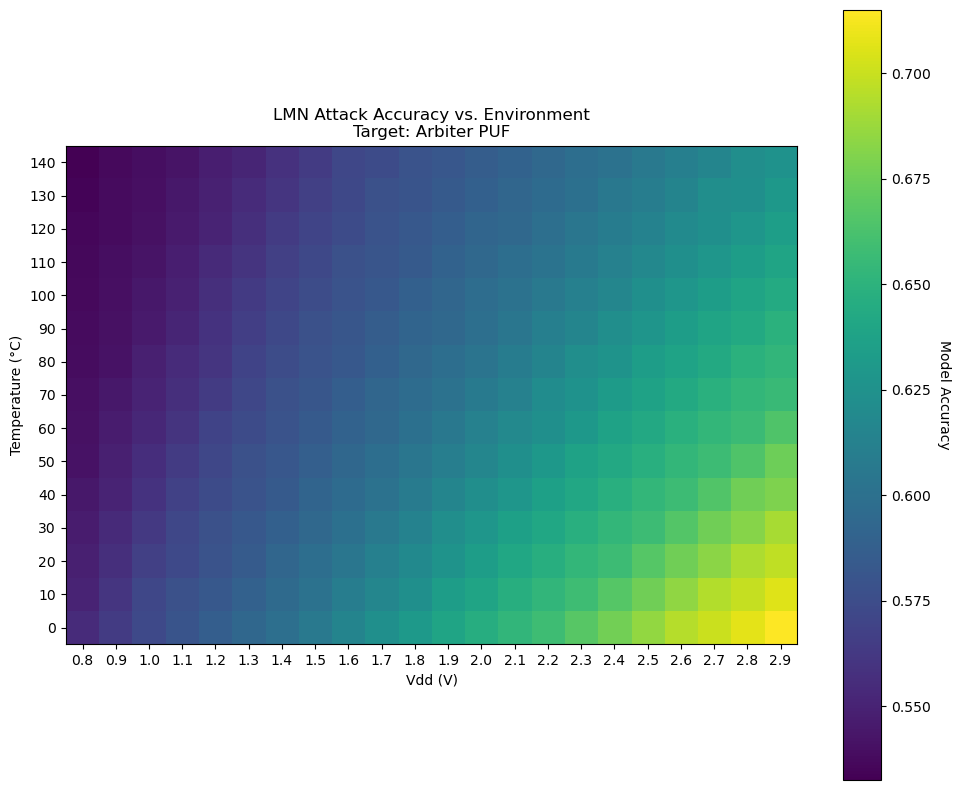

In [12]:
from pypuf.simulation import ArbiterPUF
from pypuf.io import ChallengeResponseSet
from pypuf.attack import LMNAttack, LeastSquaresRegression
from pypuf.metrics import similarity
import numpy as np

# 1. Setup Parameters
n_bits, puf_seed = 64, 123
nom_temp, nom_vdd = 25.0, 1.2
n_train, n_test = 50000, 2000
temp_range = np.arange(0, 150, 10)
vdd_range = np.round(np.arange(0.8, 3.00, 0.1), 2)

# 2. Generate Training Data at Nominal (Golden Point)
# The noisiness parameter models the thermal jitter essential for your analysis
p_nom = ArbiterPUF(n=n_bits, seed=puf_seed, noisiness=0.05, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

# --- Attack A: LMN Algorithm ---
# Approximates the Fourier spectrum of the PUF [cite: 3, 35]
# Degree 1 is used for efficient runtime in practice [cite: 18, 32]
lmn_model = LMNAttack(train_crps, deg=1).fit() #[cite: 23, 61]
lmn_model.temperature, lmn_model.vdd = nom_temp, nom_vdd

# --- Attack B: Linear Regression ---
# Fits a linear function optimal with respect to total squared error 
# Feature map transform_atf is required as the mapping is linear in features, not challenges [cite: 101, 102]
lr_model = LeastSquaresRegression(
    train_crps, 
    feature_map=lambda cs: ArbiterPUF.transform_atf(cs, k=1)[:, 0, :]
).fit() #[cite: 102, 173]
lr_model.temperature, lr_model.vdd = nom_temp, nom_vdd
lr_model.postprocessing = lr_model.postprocessing_threshold #[cite: 106]

# 3. Environmental Sweep Evaluation (Example for LMN)
acc_grid_lmn = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = ArbiterPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v)
        # Using seed=4 for evaluation CRP generation per pypuf docs [cite: 30]
        acc_grid_lmn[i, j] = similarity(p_eval, lmn_model, seed=4, N=n_test)[0] #[cite: 30]

# 4. Visualization
plot_environmental_heatmap(acc_grid_lmn, temp_range, vdd_range, "Arbiter PUF", "LMN Attack")

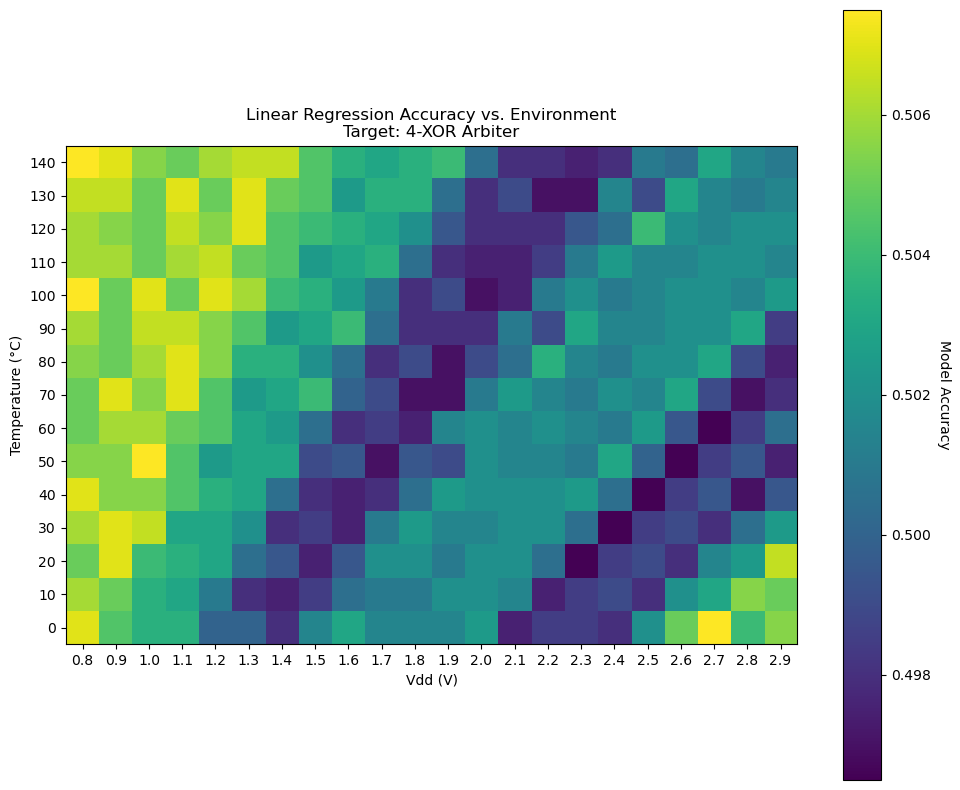

In [13]:
from pypuf.simulation import XORArbiterPUF

k_val = 4
p_nom = XORArbiterPUF(n=n_bits, k=k_val, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=100000, seed=puf_seed)

# Feature map uses k=k_val but flattens to the primary dimension 
attack = LeastSquaresRegression(
    train_crps, 
    feature_map=lambda cs: ArbiterPUF.transform_atf(cs, k=k_val)[:, 0, :]
)
model = attack.fit()
model.temperature, model.vdd = nom_temp, nom_vdd
model.postprocessing = model.postprocessing_threshold

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = XORArbiterPUF(n=n_bits, k=k_val, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, f"{k_val}-XOR Arbiter", "Linear Regression")

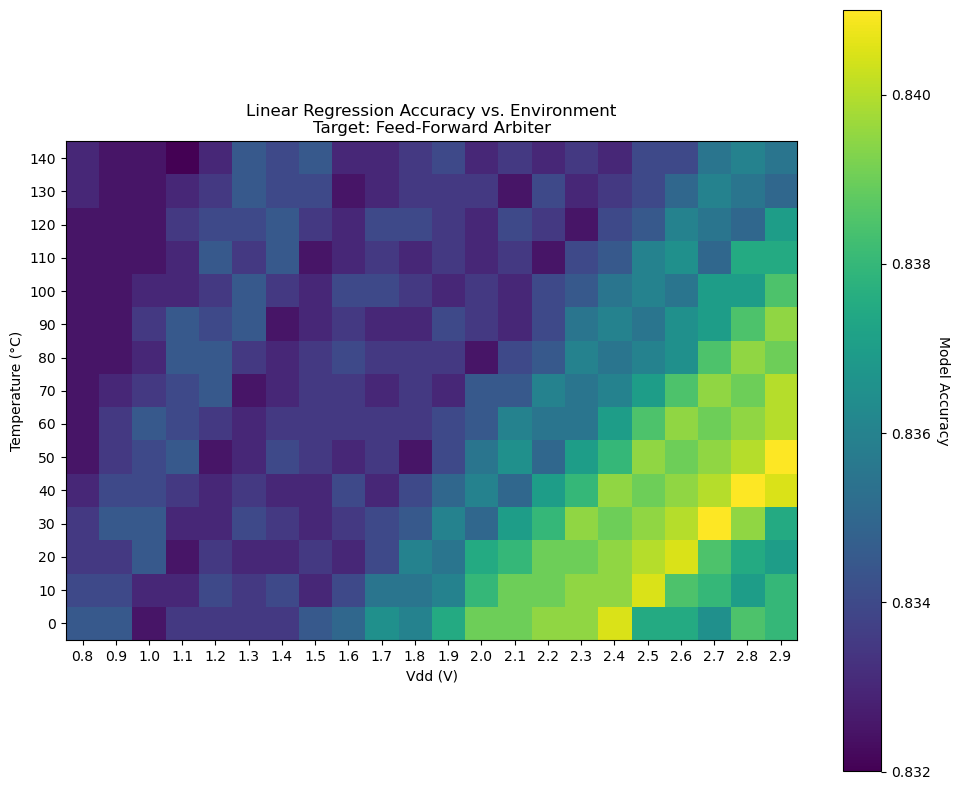

In [14]:
from pypuf.simulation import FeedForwardArbiterPUF

ff_config = [(10, 20), (30, 40)]
p_nom = FeedForwardArbiterPUF(n=n_bits, ff=ff_config, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

attack = LeastSquaresRegression(
    train_crps, 
    feature_map=lambda cs: ArbiterPUF.transform_atf(cs, k=1)[:, 0, :]
)
model = attack.fit()
model.temperature, model.vdd = nom_temp, nom_vdd
model.postprocessing = model.postprocessing_threshold

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = FeedForwardArbiterPUF(n=n_bits, ff=ff_config, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Feed-Forward Arbiter", "Linear Regression")

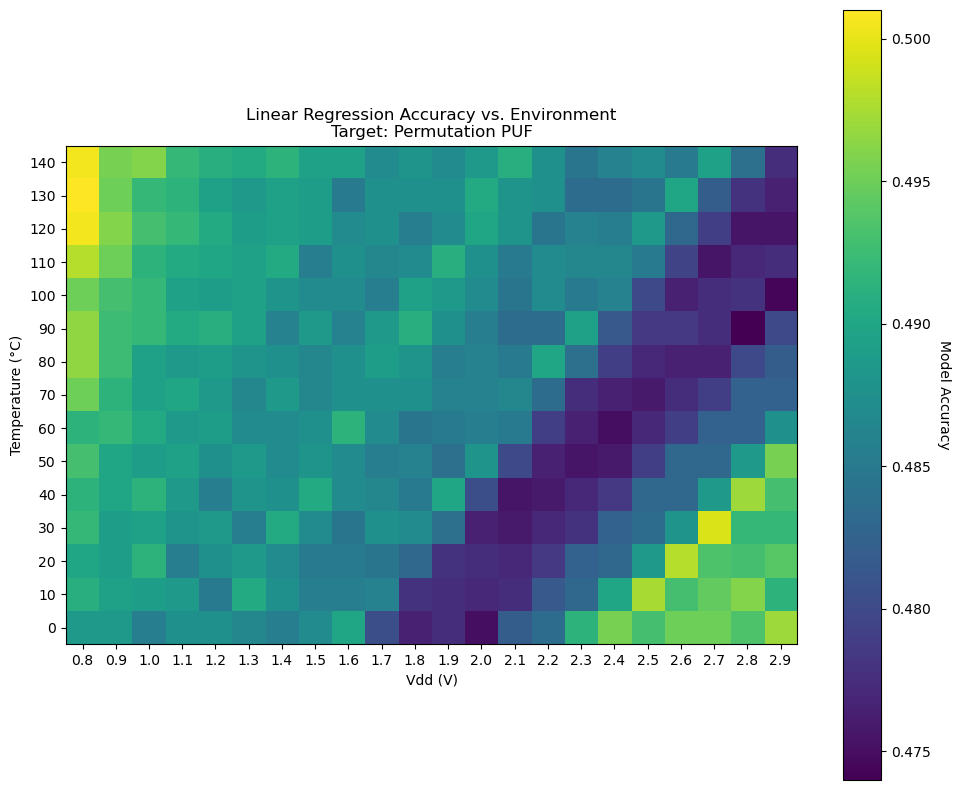

In [15]:
from pypuf.simulation import PermutationPUF

p_nom = PermutationPUF(n=n_bits, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd, k=8)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=n_train, seed=puf_seed)

attack = LeastSquaresRegression(
    train_crps, 
    feature_map=lambda cs: ArbiterPUF.transform_atf(cs, k=1)[:, 0, :]
)
model = attack.fit()
model.temperature, model.vdd = nom_temp, nom_vdd
model.postprocessing = model.postprocessing_threshold

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = PermutationPUF(n=n_bits, seed=puf_seed, temperature=t, vdd=v, k=8)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Permutation PUF", "Linear Regression")

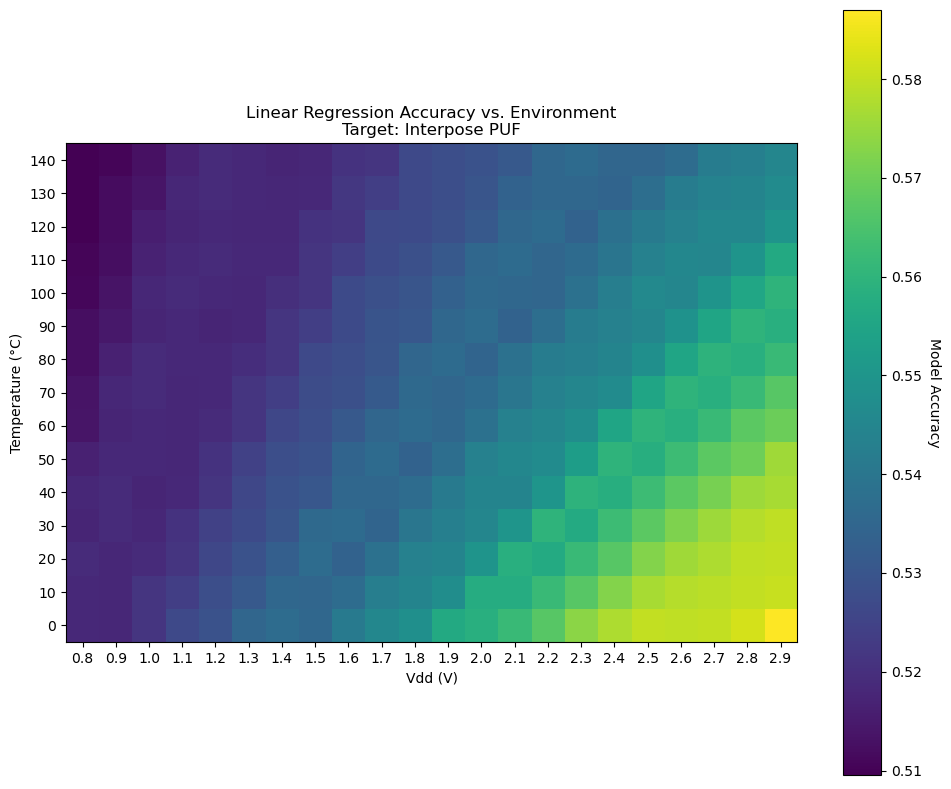

In [16]:
from pypuf.simulation import InterposePUF

p_nom = InterposePUF(n=n_bits, k_up=2, k_down=2, seed=puf_seed, temperature=nom_temp, vdd=nom_vdd)
train_crps = ChallengeResponseSet.from_simulation(p_nom, N=300000, seed=puf_seed)

# Feature mapping for Interpose treating it as a unified linear model 
attack = LeastSquaresRegression(
    train_crps, 
    feature_map=lambda cs: ArbiterPUF.transform_atf(cs, k=4)[:, 0, :]
)
model = attack.fit()
model.temperature, model.vdd = nom_temp, nom_vdd
model.postprocessing = model.postprocessing_threshold

acc_grid = np.zeros((len(temp_range), len(vdd_range)))
for i, t in enumerate(temp_range):
    for j, v in enumerate(vdd_range):
        p_eval = InterposePUF(n=n_bits, k_up=2, k_down=2, seed=puf_seed, temperature=t, vdd=v)
        acc_grid[i, j] = similarity(p_eval, model, seed=42, N=n_test)[0]

plot_environmental_heatmap(acc_grid, temp_range, vdd_range, "Interpose PUF", "Linear Regression")